In [1]:
%load_ext autoreload
%autoreload 2
    

import matplotlib.pyplot as plt
import tifffile
from PIL import Image
import numpy as np
from scipy.optimize import curve_fit
from scipy.integrate import cumulative_trapezoid
from scipy.signal import savgol_filter
import pandas as pd
import matplotlib.transforms as mtransforms
from statsmodels.nonparametric.smoothers_lowess import lowess
import cmcrameri.cm as cm

import analysis_functions as afn

In [2]:
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-nr.tif') as img:
    streak_pre_nr = np.array(img)
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak_preshot-r.tif') as img:
    streak_pre_r = np.array(img)   
with Image.open('data_shot3_raw/streak/z4290leg1_laserstreak.tif') as img:
    streak = np.array(img)   

calib = pd.read_csv('streak_calib.csv')

In [3]:
px_to_mm = calib['value'].values[0]
px_to_ns = calib['value'].values[1]

cmax = np.percentile(streak, 99)

Text(0, 0.5, 'mm')

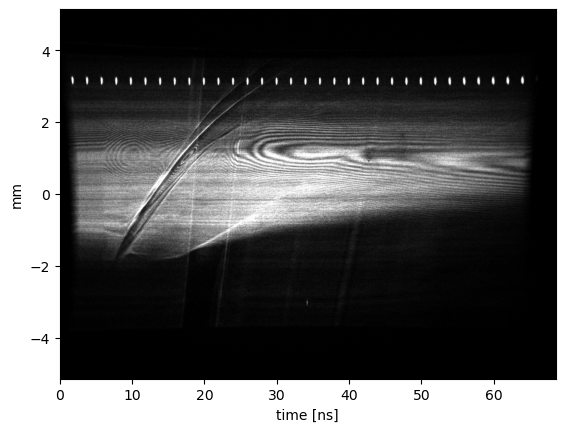

In [4]:
extent_x = streak.shape[1] * px_to_ns
extent_y = streak.shape[0] * px_to_mm
ext=[0, extent_x, -extent_y/2, extent_y/2]

plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

In [5]:
times = np.linspace(3, 5, 11)
times = np.array(times)
y_val = []
lineouts = []
for t in times:
    y, lo = afn.plot_vlineout_streak(t_ns = t, ext = ext, image =streak, return_data = True, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    lineouts.append(lo)
    y_val.append(y)
y_val = np.array(y_val)
lineouts = np.array(lineouts, dtype=object)

mask = (times > 3.8) | (times < 3.6)
times = times[mask]
y_val = y_val[mask]
lineouts = lineouts[mask]

Text(0.5, 1.0, 'Various lineouts at early times (raw data)')

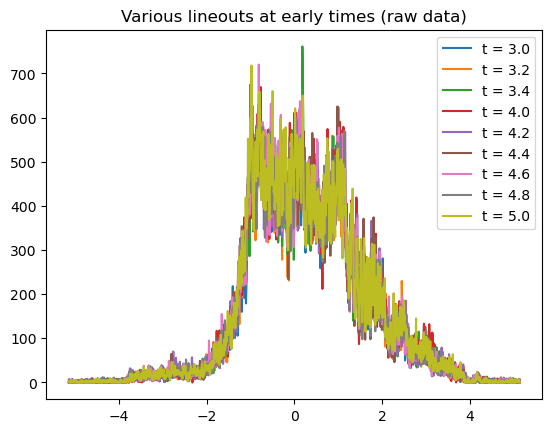

In [6]:
for i in range(len(y_val)):
    plt.plot(y_val[i],lineouts[i], label = f't = {times[i]}')
plt.legend()
plt.title('Various lineouts at early times (raw data)')

Text(0.5, 1.0, 'Moving Average Smoothing')

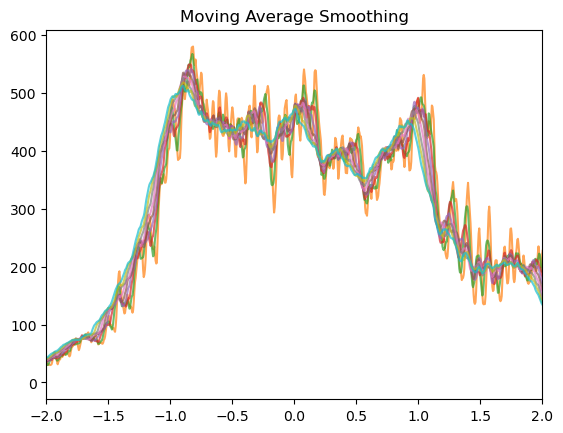

In [7]:
# smoothing: moving average
lineout_0_pd = pd.Series(lineouts[0])
for i in range(10):
    moving_avg = lineout_0_pd.rolling(window = i*5).mean()
    plt.plot(y_val[0], moving_avg, label = f'Window = {i*5}', alpha = 0.7)
# plt.plot(y_val[0], moving_avg)
# plt.legend()
plt.xlim(-2, 2)
plt.title('Moving Average Smoothing')

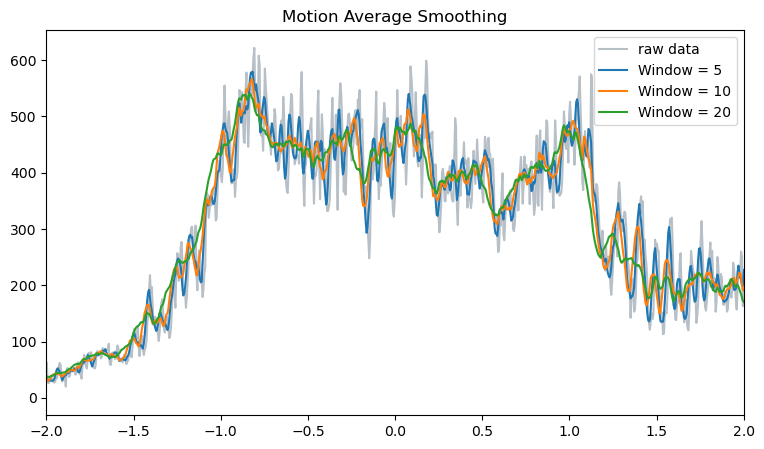

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

plt.plot(y_val[0], lineouts[0], color = 'slategray', label = 'raw data', alpha = 0.5)
i = 1
moving_avg = lineout_0_pd.rolling(window = i*5).mean()
plt.plot(y_val[0], moving_avg, label = f'Window = {i*5}')
i = 2
moving_avg = lineout_0_pd.rolling(window = i*5).mean()
plt.plot(y_val[0], moving_avg, label = f'Window = {i*5}')
i = 4
moving_avg = lineout_0_pd.rolling(window = i*5).mean()
plt.plot(y_val[0], moving_avg, label = f'Window = {i*5}')

plt.xlim(-2,2)

plt.legend()
plt.title('Motion Average Smoothing')

plt.savefig('streak_images/smoothing_early/testing/motion_avg_windows', bbox_inches = 'tight')

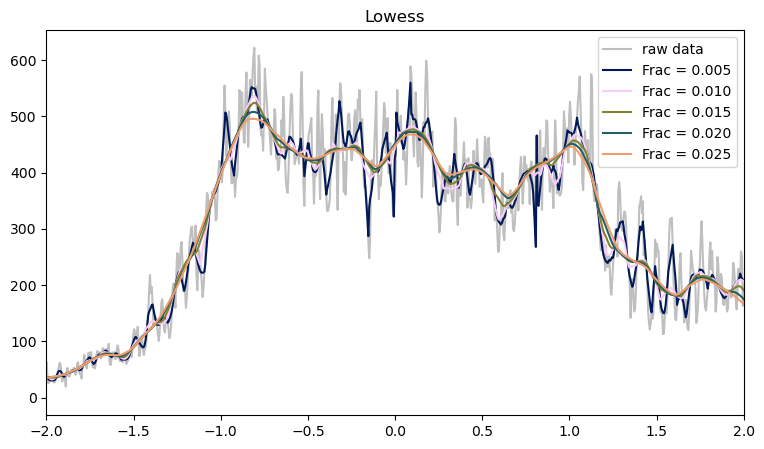

In [9]:
# smoothing: lowess
fig, ax = plt.subplots(figsize=(9, 5))
plt.plot(y_val[0], lineouts[0], color = 'gray', alpha = 0.5, label = 'raw data')
for i in range(5):
    pdf = lowess(lineouts[0], range(len(lineouts[0])), frac = 0.005*(i+1))
    plt.plot(y_val[0], pdf[:,1], label = f'Frac = {(1+i)*0.005:.3f}', color = cm.batlowS(i))

plt.legend()
plt.xlim(-2, 2)
plt.title('Lowess')

plt.savefig('streak_images/smoothing_early/testing/lowess_frac', bbox_inches = 'tight')

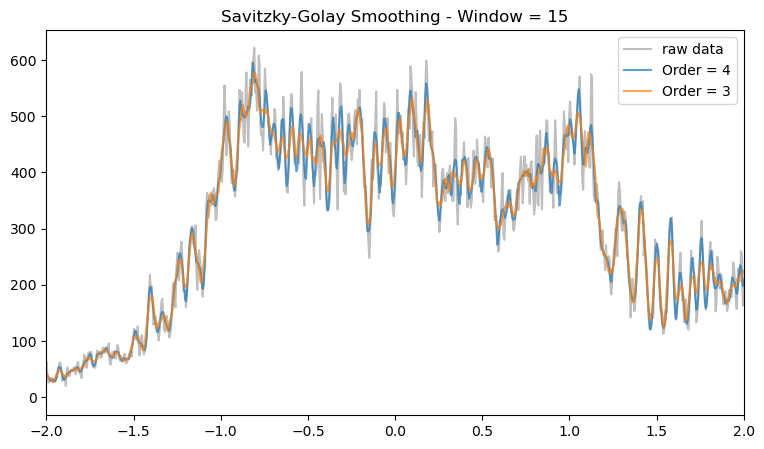

In [10]:
# savgol filter
# for i in range(10):
fig, ax = plt.subplots(figsize=(9, 5))

plt.plot(y_val[0], lineouts[0], color = 'gray', alpha = 0.5, label = 'raw data')

savgol_data = savgol_filter(lineout_0_pd, window_length = 15, polyorder = 4)
plt.plot(y_val[0], savgol_data, label = f'Order = 4', alpha = 0.7)

savgol_data = savgol_filter(lineout_0_pd, window_length = 15, polyorder = 3)
plt.plot(y_val[0], savgol_data, label = f'Order = 3', alpha = 0.7)

plt.legend()
plt.xlim(-2, 2)

plt.title('Savitzky-Golay Smoothing - Window = 15')
plt.savefig('streak_images/smoothing_early/testing/savgol_order', bbox_inches = 'tight')

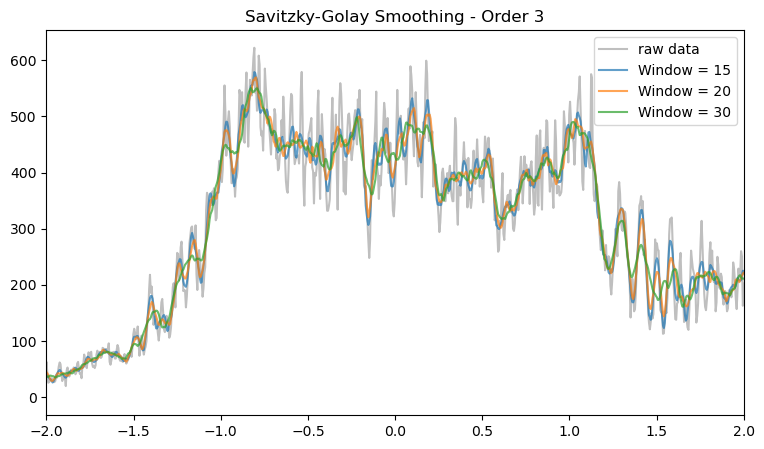

In [11]:
# savgol filter
# for i in range(10):
fig, ax = plt.subplots(figsize=(9, 5))

plt.plot(y_val[0], lineouts[0], color = 'gray', alpha = 0.5, label = 'raw data')

savgol_data = savgol_filter(lineout_0_pd, window_length = 15, polyorder = 3)
plt.plot(y_val[0], savgol_data, label = f'Window = 15', alpha = 0.7)

savgol_data = savgol_filter(lineout_0_pd, window_length = 20, polyorder = 3)
plt.plot(y_val[0], savgol_data, label = f'Window = 20', alpha = 0.7)

savgol_data = savgol_filter(lineout_0_pd, window_length = 30, polyorder = 3)
plt.plot(y_val[0], savgol_data, label = f'Window = 30', alpha = 0.7)

plt.legend()
plt.xlim(-2, 2)

plt.title('Savitzky-Golay Smoothing - Order 3')

plt.savefig('streak_images/smoothing_early/testing/savgol_window_o3', bbox_inches = 'tight')

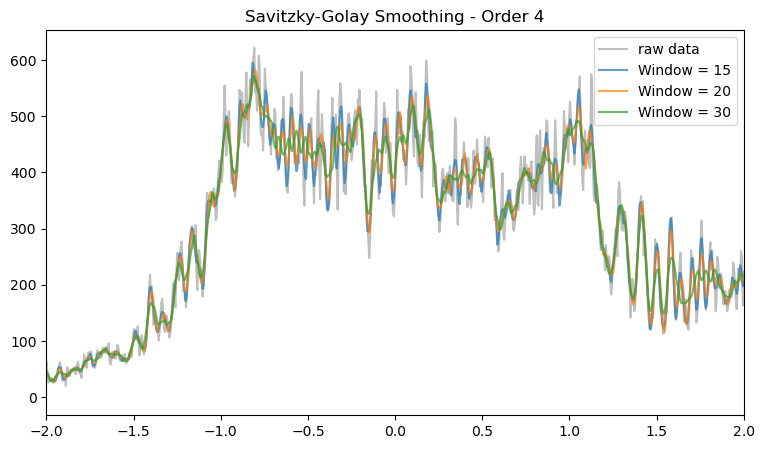

In [12]:
# savgol filter
# for i in range(10):
fig, ax = plt.subplots(figsize=(9, 5))

plt.plot(y_val[0], lineouts[0], color = 'gray', alpha = 0.5, label = 'raw data')

savgol_data = savgol_filter(lineout_0_pd, window_length = 15, polyorder = 4)
plt.plot(y_val[0], savgol_data, label = f'Window = 15', alpha = 0.7)

savgol_data = savgol_filter(lineout_0_pd, window_length = 20, polyorder = 4)
plt.plot(y_val[0], savgol_data, label = f'Window = 20', alpha = 0.7)

savgol_data = savgol_filter(lineout_0_pd, window_length = 30, polyorder = 4)
plt.plot(y_val[0], savgol_data, label = f'Window = 30', alpha = 0.7)

plt.legend()
plt.xlim(-2, 2)

plt.title('Savitzky-Golay Smoothing - Order 4')

plt.savefig('streak_images/smoothing_early/testing/savgol_window_o4', bbox_inches = 'tight')

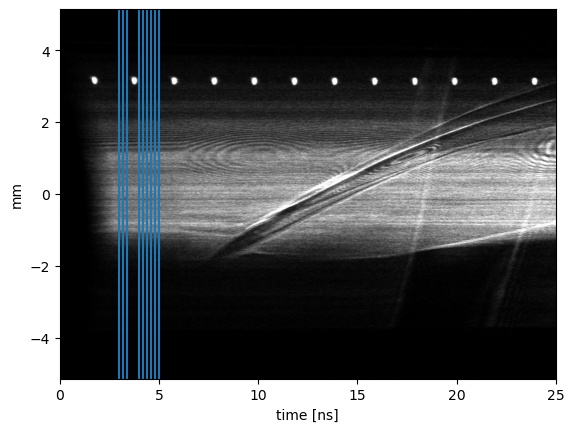

In [13]:
plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

for i in range(len(times)):
    plt.axvline(times[i])

plt.xlim(0, 25)

plt.savefig('streak_images/bkgd/lineout_positions_prelim', bbox_inches = 'tight')

Text(0, 0.5, 'Intensity')

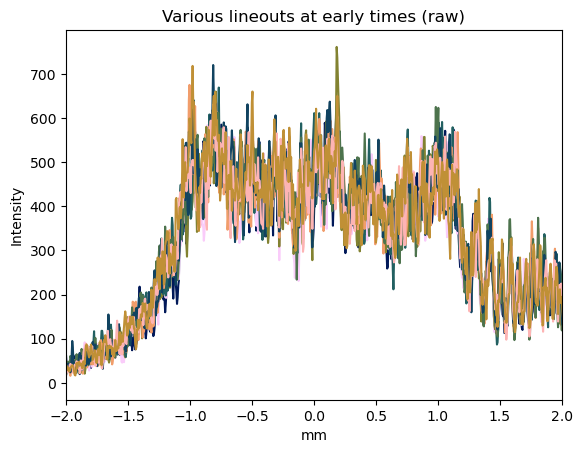

In [14]:
for i in range(len(y_val)):
    plt.plot(y_val[i],lineouts[i], label = f't = {times[i]}', color = cm.batlowS(i))
# plt.legend()
plt.title('Various lineouts at early times (raw)')
plt.xlim(-2, 2)

plt.xlabel('mm')
plt.ylabel('Intensity')

# plt.savefig('streak_images/smoothing/raw_lineouts', bbox_inches = 'tight')

In [15]:
# SAVGOL
for w in range(10):
    win_len = (w+1)*10
    for i in range(len(y_val)):
        plt.plot(y_val[i], savgol_filter(lineouts[i], window_length = win_len, polyorder = 3), label = f't = {times[i]}', color = cm.batlowS(i))
    plt.legend()
    plt.title(f'Early times lineouts (SavGol window length = {win_len})')
    plt.xlim(-2, 2)

    plt.xlabel('mm')
    plt.ylabel('Intensity')
    
    # plt.savefig(f'streak_images/smoothing_late/savgol/win_len_{win_len}', bbox_inches = 'tight')
    plt.clf()

<Figure size 640x480 with 0 Axes>

In [16]:
# MOVING AVG
for w in range(10):
    win_len = (1+w)*5
    for i in range(len(y_val)):
        moving_avg = (pd.Series(lineouts[i])).rolling(window = win_len).mean()
        plt.plot(y_val[i], moving_avg, label = f't = {times[i]}', color = cm.batlowS(i))
    plt.legend()
    plt.title(f'Early times lineouts (Moving avg window length = {win_len})')
    plt.xlim(-2, 2)

    plt.xlabel('mm')
    plt.ylabel('Intensity')
    
    # plt.savefig(f'streak_images/smoothing_late/moving_avg/win_len_{win_len}', bbox_inches = 'tight')
    plt.clf()

<Figure size 640x480 with 0 Axes>

In [17]:
# LOWESS
for f in range(10):
    fraction = (1+f)*0.002
    for i in range(len(y_val)):
        pdf = lowess(lineouts[i], range(len(lineouts[i])), frac = fraction)
        plt.plot(y_val[i], pdf[:,1], label = f't = {times[i]}', color = cm.batlowS(i))
    plt.legend()
    plt.title(f'Early times lineouts (Lowess Fraction = {fraction:.3f})')
    plt.xlim(-2, 2)

    plt.xlabel('mm')
    plt.ylabel('Intensity')
    
    # plt.savefig(f'streak_images/smoothing_late/lowess/frac_{fraction:.3f}.jpg', bbox_inches = 'tight')
    plt.clf()

<Figure size 640x480 with 0 Axes>

In [18]:
times = np.linspace(3, 5, 51)
times = np.array(times)
y_val = []
lineouts = []
for t in times:
    y, lo = afn.plot_vlineout_streak(t_ns = t, ext = ext, image =streak, return_data = True, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    lineouts.append(lo)
    y_val.append(y)
y_val = np.array(y_val)
lineouts = np.array(lineouts, dtype=object)

mask = (times > 4.0) | (times < 3.5)
times = times[mask]
y_val = y_val[mask]
lineouts = lineouts[mask]

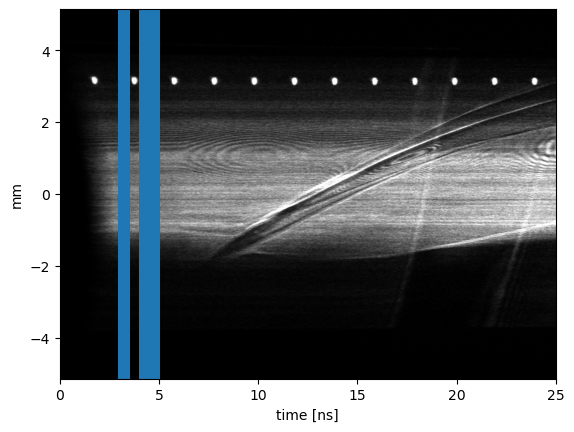

In [19]:
plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

for i in range(len(times)):
    plt.axvline(times[i])

plt.xlim(0, 25)

plt.savefig('streak_images/bkgd/lineout_positions_bkgd', bbox_inches = 'tight')

In [20]:
background = np.mean(lineouts, axis = 0)

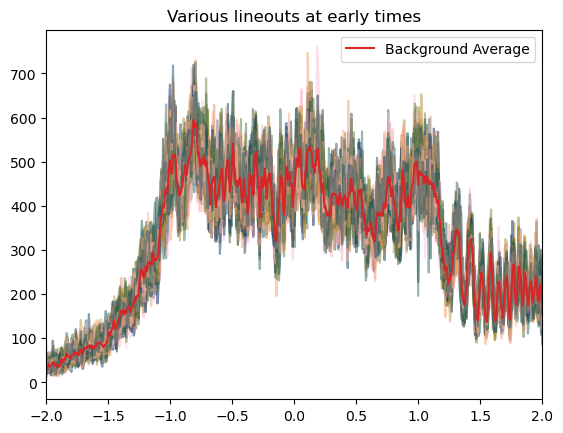

In [21]:
for i in range(len(y_val)):
    plt.plot(y_val[i],lineouts[i], color = cm.batlowS(i), alpha = 0.5)

plt.plot(y_val[0], background, color = 'tab:red', label = 'Background Average')

# plt.legend()
plt.title('Various lineouts at early times')
plt.legend()
plt.xlim(-2,2)

plt.savefig('streak_images/bkgd/raw_avg')

Text(0, 0.5, 'Intensity')

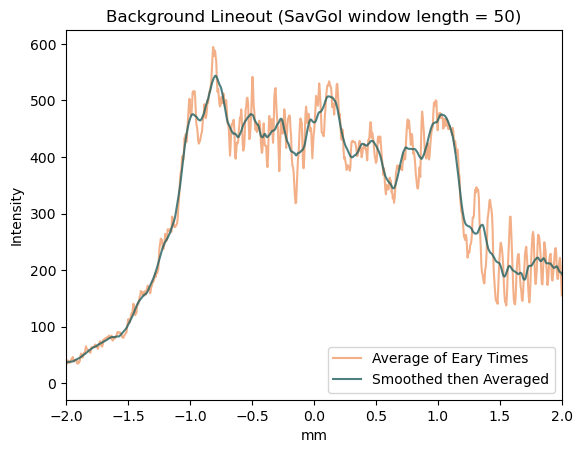

In [22]:
# background vs. smoothed background
win_len = 50
background_smoothed = np.mean(savgol_filter(lineouts, window_length = win_len, polyorder = 3), axis = 0)

plt.plot(y_val[0], background, label = 'Average of Eary Times', linewidth = 1.5, color = cm.batlowS(4), alpha = 0.8)
plt.plot(y_val[0], background_smoothed, label = 'Smoothed then Averaged', linewidth = 1.5, color = cm.batlowS(3), alpha = 0.8)

plt.title(f'Background Lineout (SavGol window length = {win_len})')
plt.xlim(-2, 2)
plt.legend()
plt.xlabel('mm')
plt.ylabel('Intensity')

# plt.savefig(f'streak_images/smoothing_early/savgol/background_savgol_{win_len}')

In [23]:
times_shock = np.linspace(10, 20, 21)
times_shock = np.array(times_shock)
y_val_shock = []
lineouts_shock = []
for t in times_shock:
    y, lo = afn.plot_vlineout_streak(t_ns = t, ext = ext, image =streak, return_data = True, output = f'streak_images/lineouts/linout_t={t}ns.jpg')
    lineouts_shock.append(lo)
    y_val_shock.append(y)
y_val_shock = np.array(y_val_shock)
lineouts_shock = np.array(lineouts_shock, dtype=object)

lineouts_shock_bkgdsub_sm = lineouts_shock - background_smoothed
lineouts_shock_bkgdsub_raw = lineouts_shock - background

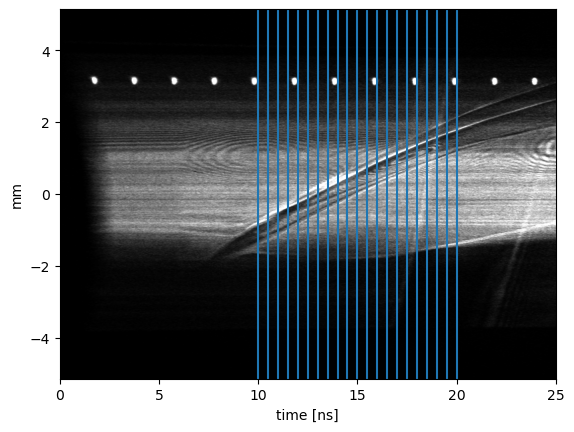

In [24]:
plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

for i in range(len(times_shock)):
    plt.axvline(times_shock[i])

plt.xlim(0, 25)

plt.savefig('streak_images/bkgd/lineout_positions_shock', bbox_inches = 'tight')

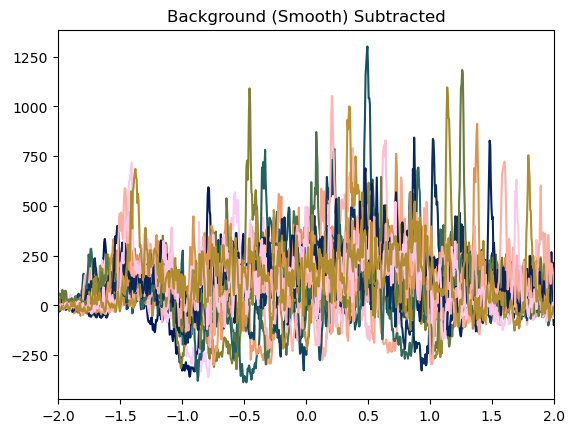

In [25]:
for i in range(len(y_val_shock)):
    plt.plot(y_val_shock[i], lineouts_shock_bkgdsub_sm[i], color = cm.batlowS(i), label = f't = {times_shock[i]}')

# plt.legend()
plt.xlim(-2,2)

plt.title('Background (Smooth) Subtracted')

plt.savefig('streak_images/bkgd/smooth_bkgd_sub')

In [26]:
# for i in range(len(y_val_shock)):
for i in range(len(y_val_shock)):
    plt.plot(y_val_shock[i], savgol_filter(lineouts_shock_bkgdsub_raw[i], window_length = win_len, polyorder = 3), color = cm.batlowS(4), label = f'Raw Background', alpha = 0.8)
    plt.plot(y_val_shock[i], savgol_filter(lineouts_shock_bkgdsub_sm[i], window_length = win_len, polyorder = 3), color = cm.batlowS(3), label = f'Smoothed Background', alpha = 0.8)
    # plt.savefig(f'streak_images/bkgd/raw_bkgd_sub_t={times_shock[i]}.jpg')
    plt.legend()
    plt.xlim(-2,2)
    plt.title(f'Background Subtracted Data, Smoothed: t = {times_shock[i]}')
    plt.savefig(f'streak_images/bkgd/bkgd_sub_comp_smooth_t={times_shock[i]}.jpg')
    plt.clf()

<Figure size 640x480 with 0 Axes>

In [27]:
for i in range(len(y_val_shock)):
    plt.plot(y_val_shock[i], savgol_filter(lineouts_shock_bkgdsub_raw[i], window_length = win_len, polyorder = 3), color = cm.batlowS(4), label = f'Lineout', alpha = 0.8)
    plt.legend()
    plt.xlim(-2,2)
    plt.ylim(-400,800)
    plt.title(f'Shock Lineout at t = {times_shock[i]}')
    plt.xlabel('Position [mm]')
    plt.ylabel('Intensity')
    plt.savefig(f'streak_images/lineouts/raw_t={times_shock[i]}.jpg')
    plt.clf()

<Figure size 640x480 with 0 Axes>

In [28]:
i_val_shock = savgol_filter(lineouts_shock_bkgdsub_raw, window_length = 30, polyorder = 3)

In [29]:
# t = 10
absmax = []
absmin = []
start_index, end_index = -2,2

# for i in range(len(y_val_shock)):
for i in range(len(y_val_shock)):
    plt.plot(y_val_shock[i], lineouts_shock_bkgdsub_raw[i], color = 'cornflowerblue', label = f'Lineout', alpha = 0.8)

    x_data = y_val_shock[i]
    y_data = lineouts_shock_bkgdsub_raw[i]

    mask = (x_data >= start_index) & (x_data <= end_index)
    x_fit, y_fit = x_data[mask],y_data[mask]

    absmax.append(x_fit[np.argmax(y_fit)])
    absmin.append(x_fit[np.argmin(y_fit)])

    # plt.axvline(absmax[i], label = 'Absolute Maximum', linestyle = '--', color = cm.batlowS(3))
    # plt.axvline(absmin[i], label = 'Absolute Minimum', linestyle = '--', color = cm.batlowS(8))

    plt.legend()
    plt.xlim(-2,2)
    plt.ylim(-400,800)
    plt.title(f'Shock Lineout at t = {times_shock[i]}')
    plt.xlabel('Position [mm]')
    plt.ylabel('Intensity')
    plt.savefig(f'streak_images/lineouts/ns_t={times_shock[i]}.jpg')
    plt.clf()

<Figure size 640x480 with 0 Axes>

In [30]:
# t = 10
absmax = []
absmin = []
start_index, end_index = -2,2

# for i in range(len(y_val_shock)):
for i in range(len(y_val_shock)):
    plt.plot(y_val_shock[i], i_val_shock[i], color = 'cornflowerblue', label = f'Lineout', alpha = 0.8)

    x_data = y_val_shock[i]
    y_data = i_val_shock[i]

    mask = (x_data >= start_index) & (x_data <= end_index)
    x_fit, y_fit = x_data[mask],y_data[mask]

    absmax.append(x_fit[np.argmax(y_fit)])
    absmin.append(x_fit[np.argmin(y_fit)])

    # plt.axvline(absmax[i], label = 'Absolute Maximum', linestyle = '--', color = cm.batlowS(3))
    # plt.axvline(absmin[i], label = 'Absolute Minimum', linestyle = '--', color = cm.batlowS(8))

    plt.legend()
    plt.xlim(-2,2)
    plt.ylim(-400,800)
    plt.title(f'Shock Lineout at t = {times_shock[i]}')
    plt.xlabel('Position [mm]')
    plt.ylabel('Intensity')
    plt.savefig(f'streak_images/lineouts/dens_t={times_shock[i]}.jpg')
    plt.clf()

<Figure size 640x480 with 0 Axes>

In [31]:
win_len = 30
i_val_shock = savgol_filter(lineouts_shock_bkgdsub_raw, window_length = win_len, polyorder = 3)

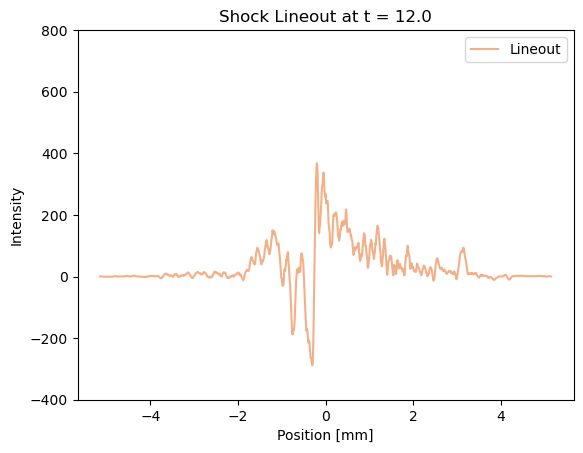

In [32]:
top_line = []
mid_line = []
bottom_line = []

# t = 10
ind = 4

start_index, end_index = -0.1,0.5

plt.plot(y_val_shock[ind], i_val_shock[ind], color = cm.batlowS(4), label = f'Lineout', alpha = 0.8)

x_data = y_val_shock[ind]
y_data = i_val_shock[ind]

mask = (x_data >= start_index) & (x_data <= end_index)
x_fit, y_fit = x_data[mask],y_data[mask]

top_line.append(x_fit[np.argmax(y_fit)])

# plt.axvline(absmax[ind], label = 'Absolute Maximum', linestyle = '--', color = cm.batlowS(3))
# plt.axvline(absmin[ind], label = 'Absolute Minimum', linestyle = '--', color = cm.batlowS(8))
# plt.axvline(top_line, label = 'Top Line', linestyle = '--', color = cm.batlowS(1))

plt.legend()
# plt.xlim(-2,2)
plt.ylim(-400,800)
plt.title(f'Shock Lineout at t = {times_shock[ind]}')
plt.xlabel('Position [mm]')
plt.ylabel('Intensity')
plt.show()

In [33]:
for ind in range(len(times_shock)):
    x_data = y_val_shock[ind]
    y_data = i_val_shock[ind]
    
    unperturbed_mask = (x_data > 1.5) & (x_data < 2.0)
    baseline = np.mean(y_data[unperturbed_mask])
    y_corrected = y_data - 0
    
    dn_dx = cumulative_trapezoid(y_corrected, x_data, initial=0)
    
    delta_n = cumulative_trapezoid(dn_dx, x_data, initial=0)
    
    density_profile = delta_n
    
    fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)
    
    # Raw Signal
    axs[0].plot(x_data, y_corrected, color='coral')
    axs[0].set_title('Intensity Lineout')
    axs[0].set_ylabel('Intensity')
    axs[0].grid(True)
    
    # First Integration
    axs[1].plot(x_data, dn_dx, color='blue')
    axs[1].set_title('$dn/dx$ (First Integration)')
    axs[1].set_ylabel('dn/dx')
    axs[1].grid(True)
    
    # Second Integration
    axs[2].plot(x_data, density_profile, color='green')
    axs[2].set_title(r'Density Profile (Second Integration)')
    axs[2].set_ylabel(r'Relative Density')
    axs[2].set_xlabel(r'Position [mm]')
    axs[2].grid(True)
    
    plt.tight_layout()
    plt.savefig(f'streak_images/dens/full_t={times_shock[ind]}.jpg')
    plt.close()

In [34]:
#not fitted
for ind in range(len(times_shock)):
    x_data = y_val_shock[ind]
    y_data = i_val_shock[ind]
    
    perturbed_mask = (x_data <2) & (x_data > - 2.0)
    y_corrected = y_data[perturbed_mask] # no baseline correction now
    x_data = x_data[perturbed_mask]
    
    dn_dx = cumulative_trapezoid(y_corrected, x_data, initial=0)
    
    delta_n = cumulative_trapezoid(dn_dx, x_data, initial=0)
    
    density_profile = delta_n
    
    fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)
    
    # Raw Signal
    axs[0].plot(x_data, y_corrected, color='coral')
    axs[0].set_title('Intensity Lineout')
    axs[0].set_ylabel('Intensity')
    axs[0].grid(True)
    
    # First Integration
    axs[1].plot(x_data, dn_dx, color='blue')
    axs[1].set_title('$dn/dx$ (First Integration)')
    axs[1].set_ylabel('dn/dx')
    axs[1].grid(True)
    
    # Second Integration
    axs[2].plot(x_data, density_profile, color='green')
    axs[2].set_title(r'Density Profile (Second Integration)')
    axs[2].set_ylabel(r'Relative Density')
    axs[2].set_xlabel(r'Position [mm]')
    axs[2].grid(True)
    
    plt.tight_layout()
    plt.savefig(f'streak_images/dens/dom_4_t={times_shock[ind]}.jpg')
    plt.close()

In [35]:
A1_guess = [-1, -0.8, -0.5, -0.5, 0, 0, 0, 0, 0, 0, 0, 0.8, 0.8, 0, 0, 1]
A2_guess = [-0.5, -0.4, -0.3,-0.3, 0, 0, 0, 0, 0.5, 0, 0, 1, 1, 0, 0, 1.2]

bounds_12 = [0.7, 1.2]
bounds_10 = [0.5, 1]
bounds_8 = [-0.2, 0.7]
bounds_6 = [-0.5,0.5]

10.5


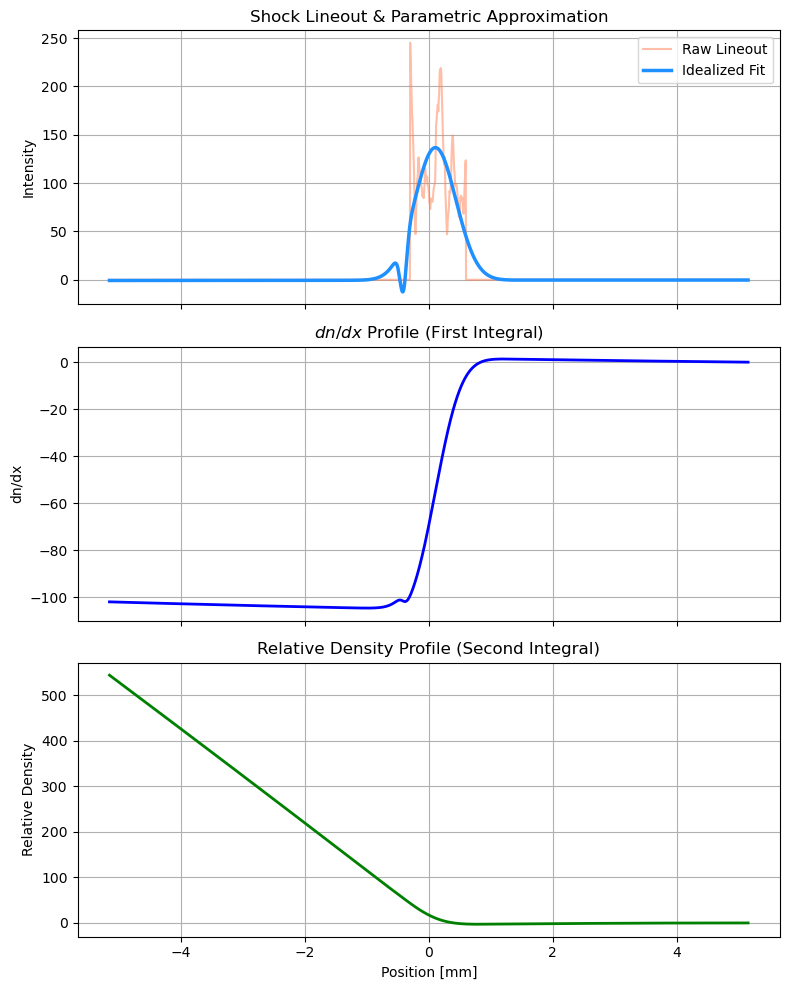

In [37]:
ind = 1
x_data = y_val_shock[ind]
y_data = i_val_shock[ind]

print(times_shock[ind])

x = x_data
y_raw = y_data
y_raw = np.where(x > 0.6, 0, y_raw)
y_raw = np.where(x < -0.3, 0, y_raw)

# --- 2. Define the Parametric Model ---
def shock_model(x, x1, w1, A1, x2, w2, A2, xs, ws, As):
    peak_neg = A1 * np.exp(-((x - x1) / w1)**2)
    peak_pos = A2 * np.exp(-((x - x2) / w2)**2)
    step = As * 0.5 * (1 + np.tanh((x - xs) / ws))
    return peak_neg + peak_pos + step

# --- 3. Set Initial Guesses (Crucial for Curve Fitting!) ---
# Based on your t=10.0 plot:
# Negative peak is around -1.0, Positive is around -0.7, Step transition is around -0.5
initial_guesses = [
    A1_guess[ind],  0.2, -300,  # x1, w1, A1 (Negative peak)
    A2_guess[ind],  0.2,  350,  # x2, w2, A2 (Positive peak)
    0,  0.2,   50   # xs, ws, As (Step/Plateau)
]

# Fit the model to the raw data
popt, pcov = curve_fit(shock_model, x, y_raw, p0=initial_guesses)

# Generate the clean, idealized curve from the fit
y_fit = shock_model(x, *popt)

# --- 4. Integrate the Idealized Curve ---
# Because y_fit has zero high-frequency noise, the integration is perfectly stable!
dn_dx = cumulative_trapezoid(y_fit, x, initial=0) 
dn_dx = dn_dx 
density = cumulative_trapezoid(dn_dx, x, initial=0)

# --- 5. Plot the Results ---
fig, axs = plt.subplots(3, 1, figsize=(8, 10), sharex=True)

# Top: Raw vs Fit
axs[0].plot(x, y_raw, color='coral', alpha=0.5, label='Raw Lineout')
axs[0].plot(x, y_fit, color='dodgerblue', linewidth=2.5, label='Idealized Fit')
axs[0].set_title('Shock Lineout & Parametric Approximation')
axs[0].set_ylabel('Intensity')
axs[0].legend()
axs[0].grid(True)

# Middle: Clean dn/dx
axs[1].plot(x, dn_dx, color='blue', linewidth=2)
axs[1].set_title('$dn/dx$ Profile (First Integral)')
axs[1].set_ylabel('dn/dx')
axs[1].grid(True)

# Bottom: Clean Density
axs[2].plot(x, density, color='green', linewidth=2)
axs[2].set_title('Relative Density Profile (Second Integral)')
axs[2].set_ylabel('Relative Density')
axs[2].set_xlabel('Position [mm]')
axs[2].grid(True)

plt.tight_layout()
plt.savefig(f'streak_images/dens/param_t={times_shock[ind]}.jpg')
plt.show()

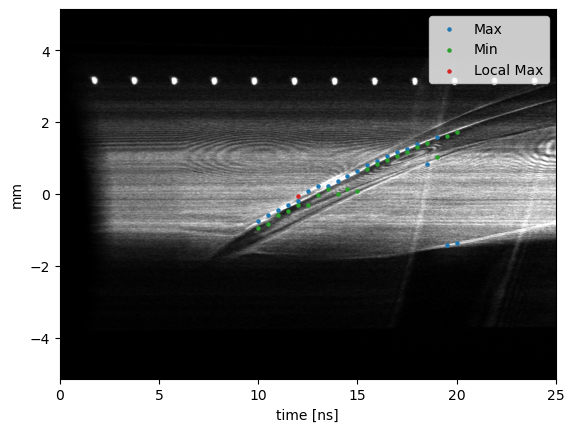

In [38]:
plt.imshow(streak, cmap = 'grey', extent=ext, aspect='auto')
plt.clim(0, cmax)
plt.xlabel('time [ns]')
plt.ylabel('mm')

plt.scatter(times_shock, absmax, color = 'tab:blue', s = 5, label = 'Max')
plt.scatter(times_shock, absmin, color = 'tab:green', s = 5, label = 'Min')
plt.scatter(times_shock[4], top_line, color = 'tab:red', s = 5, label = 'Local Max')

plt.xlim(0, 25)
plt.legend()

plt.savefig('streak_images/bkgd/lineout_positions_shock', bbox_inches = 'tight')